The questions I'm answering:

Does the most prominent type of bike lane (protected, buffered, etc) in a community affect bike usage and which types of lanes have the most crashes? How does this data compare against the hardship index of each area?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# to deal with geom
# %pip install shapely
# from shapely import wkt
# %pip install geopandas
# import geopandas as gpd

# loading in needed data

# bike routes (I will be looking at location and types of bike lanes)
bike_routes = pd.read_csv('data/Bike_Routes_20261123.csv')

# crashes
bike_crashes = pd.read_csv('data/Traffic_Crashes_-_Crashes_20261123.csv')

/var/folders/w3/gfsy265d0zn31yf8gdmr1gvw0000gq/T/ipykernel_54680/3651358630.py:17: DtypeWarning: Columns (32: WORKERS_PRESENT_I) have mixed types. Specify dtype option on import or set low_memory=False.
  bike_crashes = pd.read_csv('data/Traffic_Crashes_-_Crashes_20261123.csv')


In [2]:
# Cleaning Data

# dropping unneeded columns
bike_routes = bike_routes.drop(columns=['MI_CTRLINE', 'CONTRAFLOW'])
bike_crashes = bike_crashes.drop(columns=['CRASH_DATE_EST_I', "DAMAGE", 'INJURIES_FATAL', 'INJURIES_INCAPACITATING', "INJURIES_NON_INCAPACITATING",'INTERSECTION_RELATED_I','INJURIES_REPORTED_NOT_EVIDENT', "INJURIES_NO_INDICATION", "INJURIES_UNKNOWN", 'CRASH_DATE', 'POSTED_SPEED_LIMIT', 'TRAFFIC_CONTROL_DEVICE', 'DEVICE_CONDITION', 'WEATHER_CONDITION', 'LIGHTING_CONDITION', 'LANE_CNT', "ALIGNMENT","ROADWAY_SURFACE_COND","ROAD_DEFECT","REPORT_TYPE", "DATE_POLICE_NOTIFIED", 
                                          "BEAT_OF_OCCURRENCE","PHOTOS_TAKEN_I","STATEMENTS_TAKEN_I","DOORING_I","WORK_ZONE_I","WORK_ZONE_TYPE","WORKERS_PRESENT_I","NUM_UNITS","CRASH_MONTH", "CRASH_HOUR","CRASH_DAY_OF_WEEK","IDOT_CONTROL_NO"])

# taking out crashes that don't occur in the street where the bike lines are
bike_crashes[(bike_crashes['TRAFFICWAY_TYPE'] != 'ALLEY') & (bike_crashes['TRAFFICWAY_TYPE'] != 'PARKING LOT')]



,CRASH_RECORD_ID,FIRST_CRASH_TYPE,TRAFFICWAY_TYPE,CRASH_TYPE,NOT_RIGHT_OF_WAY_I,HIT_AND_RUN_I,PRIM_CONTRIBUTORY_CAUSE,SEC_CONTRIBUTORY_CAUSE,STREET_NO,STREET_DIRECTION,STREET_NAME,MOST_SEVERE_INJURY,INJURIES_TOTAL,LATITUDE,LONGITUDE,LOCATION
0,253baed18e45297fd0f7a5f652ce51bb8785801112938a...,PEDALCYCLIST,NOT DIVIDED,INJURY AND / OR TOW DUE TO CRASH,NaN,NaN,UNABLE TO DETERMINE,UNABLE TO DETERMINE,3151,W,ARMITAGE AVE,NONINCAPACITATING INJURY,1,41.917292,-87.706882,POINT (-87.706882237658 41.91729237245)
1,087040087f8cd5775c78478942f12e32709c34dce781c1...,PEDALCYCLIST,DIVIDED - W/MEDIAN (NOT RAISED),INJURY AND / OR TOW DUE TO CRASH,NaN,NaN,UNABLE TO DETERMINE,UNABLE TO DETERMINE,1628,W,BELMONT AVE,NONINCAPACITATING INJURY,1,41.939790,-87.669843,POINT (-87.669842823961 41.93978985369)
2,1d63370bbae72bff5ddf196b32495dd05c4c12693a0b79...,PEDALCYCLIST,Y-INTERSECTION,NO INJURY / DRIVE AWAY,NaN,NaN,UNABLE TO DETERMINE,NOT APPLICABLE,799,W,26TH ST,NO INDICATION OF INJURY,0,NaN,NaN,NaN
3,74be48f9c96e945b5e65a622520ed800976516bb0b9016...,PEDALCYCLIST,NOT DIVIDED,NO INJURY / DRIVE AWAY,NaN,NaN,UNABLE TO DETERMINE,NOT APPLICABLE,3100,N,HALSTED ST,NO INDICATION OF INJURY,0,NaN,NaN,NaN
4,1784740117160c0daaf8d6c19b2b4f3043e78a1679a951...,PEDALCYCLIST,FOUR WAY,NO INJURY / DRIVE AWAY,NaN,Y,FAILING TO YIELD RIGHT-OF-WAY,FAILING TO YIELD RIGHT-OF-WAY,2199,E,HAYES DR,NO INDICATION OF INJURY,0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19461,393b4658c22aedc3e1b33b33bffbe4510582bf57205920...,PEDALCYCLIST,FOUR WAY,INJURY AND / OR TOW DUE TO CRASH,NaN,Y,DISREGARDING TRAFFIC SIGNALS,DRIVING SKILLS/KNOWLEDGE/EXPERIENCE,4403,N,LINCOLN AVE,NONINCAPACITATING INJURY,1,41.961524,-87.683758,POINT (-87.683757975962 41.961524002559)
19462,b06a7105546d82ee1c136136d82e3d0ba09335028b418f...,PEDALCYCLIST,DIVIDED - W/MEDIAN (NOT RAISED),INJURY AND / OR TOW DUE TO CRASH,NaN,NaN,UNABLE TO DETERMINE,UNABLE TO DETERMINE,5022,N,BROADWAY,INCAPACITATING INJURY,1,41.973443,-87.659936,POINT (-87.659936020865 41.97344275976)
19463,26bf4e1144ed70317fc72d0bd919ebc340de83f54af22f...,PEDALCYCLIST,NOT DIVIDED,NO INJURY / DRIVE AWAY,NaN,NaN,DRIVING ON WRONG SIDE/WRONG WAY,UNABLE TO DETERMINE,759,E,79TH ST,NO INDICATION OF INJURY,0,41.751176,-87.605274,POINT (-87.60527365367 41.751175614967)
19464,2d87ec16e519776f865200d1f6541a38dfb04dd09eb148...,PEDALCYCLIST,DIVIDED - W/MEDIAN (NOT RAISED),INJURY AND / OR TOW DUE TO CRASH,NaN,NaN,UNABLE TO DETERMINE,NOT APPLICABLE,2298,N,PULASKI RD,INCAPACITATING INJURY,1,41.922518,-87.727167,POINT (-87.727167282051 41.922518317174)


In [3]:
# handling missing values
bike_routes.isna().sum()

bike_crashes.isna().sum()

# there is no way to fill in this information with the data provided, and it was only 33 out of 18,712 rows.
bike_crashes = bike_crashes.dropna(subset='LOCATION')

In [4]:
# checking data types
bike_routes.dtypes
bike_crashes.dtypes

#bike_routes['the_geom'] = bike_routes['the_geom'].apply(
#    lambda x: list(wkt.loads(x).geoms[0].coords)
#)



CRASH_RECORD_ID                str
FIRST_CRASH_TYPE               str
TRAFFICWAY_TYPE                str
CRASH_TYPE                     str
NOT_RIGHT_OF_WAY_I             str
HIT_AND_RUN_I                  str
PRIM_CONTRIBUTORY_CAUSE        str
SEC_CONTRIBUTORY_CAUSE         str
STREET_NO                    int64
STREET_DIRECTION               str
STREET_NAME                    str
MOST_SEVERE_INJURY             str
INJURIES_TOTAL               int64
LATITUDE                   float64
LONGITUDE                  float64
LOCATION                       str
dtype: object

In [5]:
bike_crashes['LOCATION'].iloc[0]

#bike_crashes['LOCATION'] = bike_crashes['LOCATION'].apply(
#    lambda x: tuple(map(float, x.replace('POINT (', '').replace(')', '').split()))
#)



'POINT (-87.706882237658 41.91729237245)'

In [6]:
# renaming columns
# bike_routes = bike_routes.rename(columns={'the_geom':'COORDINATES'})
bike_routes = bike_routes.rename(columns={'ST_NAME':'STREET_NAME'})

In [7]:
# Merging data

# by street name
bike_merged = bike_crashes.merge(bike_routes, on='STREET_NAME')

In [10]:
# Grouping Data
crash_counts = bike_merged.groupby('DISPLAYROU').size().reset_index(name='num_crashes')

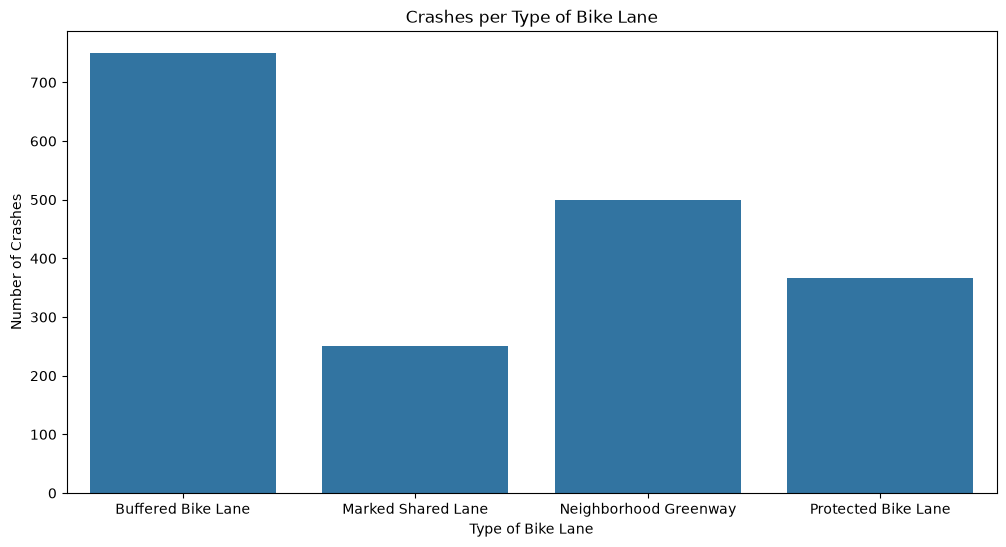

In [15]:
# Visualizing Data
plt.figure(figsize=(12, 6))
sns.barplot(data=crash_counts, x='DISPLAYROU', y='num_crashes')
plt.xlabel('Type of Bike Lane')
plt.ylabel('Number of Crashes')
plt.title('Crashes per Type of Bike Lane')
plt.show()